# Outra rede: os modelos do 2017 no CSE-CIC-IDS2018

Até aqui, treino e teste vieram da mesma rede de laboratório. Este notebook leva os modelos
treinados no CIC-IDS2017 corrigido para o **CSE-CIC-IDS2018** corrigido, do mesmo laboratório e com
o mesmo extrator de fluxos, mas com outras máquinas, numa rede na AWS
([ADR 0011](../docs/adr/0011-outra-rede.md)). São 63 milhões de fluxos em 10 dias.

Três perguntas:

1. O que os modelos aprenderam em 2017 vale em 2018, com o limiar escolhido em 2017?
2. Os atalhos suspeitos (a janela TCP, que identifica a máquina, e o protocolo, já que todos os
   ataques de 2017 são TCP) atrapalham fora do laboratório de origem?
3. Recalibrar o limiar com um dia de tráfego normal da rede nova, sem nenhum ataque, resolve?

**Como rodar:** com o zip em `data/external/` e os modelos do 2017 corrigido treinados,
`nids score data/external/CSECICIDS2018_improved.zip --model xgb_temporal --model
xgb_temporal_sem_tcp --model ae_unseen --model iforest_unseen` grava os scores em
`data/cse2018/scores.parquet` (cerca de uma hora). O notebook lê esse arquivo.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from nids import schema

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
scores = pd.read_parquet(ROOT / "data" / "cse2018" / "scores.parquet")
MODELS = {
    "xgb_temporal": "XGBoost",
    "xgb_temporal_sem_tcp": "XGBoost sem TCP",
    "ae_unseen": "Autoencoder",
    "iforest_unseen": "Isolation Forest",
}
MODEL_DIR = ROOT / "models" / "improved"
THRESHOLDS_2017 = {
    name: json.loads((MODEL_DIR / name / "metadata.json").read_text())["threshold"]
    for name in MODELS
}
FAMILIES = ["DoS", "DDoS", "Bot", "BruteForce", "PortScan", "WebAttack", "Infiltration"]
CALIBRATION_DAY = "2018-02-14"

family = scores[schema.FAMILY].astype(str).to_numpy()
date = scores["date"].astype(str).to_numpy()
benign = family == schema.BENIGN
udp = scores["protocol"].to_numpy() == 17

# Posições 1 e 2 da paleta categórica: a cor segue o limiar
COLORS = {"limiar de 2017": "#2a78d6", "limiar recalibrado": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 20, "display.width", 140)


def fmt(value):
    if pd.isna(value):
        return "—"
    return f"{value:,.0f}".replace(",", ".") if abs(value) > 1 else f"{value:.3f}"


def evaluate(alarm, keep=None):
    # Revocação por família, DDoS por UDP, revocação total e FPR, só nos fluxos de keep
    keep = np.ones(len(alarm), bool) if keep is None else keep
    attack = keep & ~benign

    def rate(mask):
        return alarm[mask].mean() if mask.any() else np.nan

    row = {f: rate(keep & (family == f)) for f in FAMILIES}
    row["DDoS por UDP"] = rate(keep & (family == "DDoS") & udp)
    row["total"] = alarm[attack].mean()
    row["FPR"] = alarm[keep & benign].mean()
    row["alarmes falsos"] = (alarm & keep & benign).sum()
    return row

## 1. O conjunto de 2018

In [2]:
composition = pd.crosstab(scores["date"], scores[schema.FAMILY]).reindex(
    columns=[schema.BENIGN, *FAMILIES], fill_value=0
)
composition.loc["total"] = composition.sum()
display(composition.map(fmt))
udp_ddos = (udp & (family == "DDoS")).sum()
print(f"{len(scores):,} fluxos; {(~benign).sum():,} de ataque; DDoS por UDP: {udp_ddos:,}")

family,BENIGN,DoS,DDoS,Bot,BruteForce,PortScan,WebAttack,Infiltration
date,,,,,,,,
2018-02-14,5.802.010,0.000,0.000,0.000,94.197,0.000,0.000,0.000
2018-02-15,5.377.039,31.050,0.000,0.000,0.000,0.000,0.000,0.000
2018-02-16,5.585.342,1.803.160,0.000,0.000,0.000,0.000,0.000,0.000
2018-02-20,5.762.439,0.000,289.772,0.000,0.000,0.000,0.000,0.000
2018-02-21,5.876.202,0.000,1.083.167,0.000,0.000,0.000,0.000,0.000
2018-02-22,6.068.660,0.000,0.000,0.000,0.000,0.000,125,0.000
2018-02-23,5.973.339,0.000,0.000,0.000,0.000,0.000,158,0.000
2018-02-28,6.516.815,0.000,0.000,0.000,0.000,49.740,0.000,88
2018-03-01,6.509.273,0.000,0.000,0.000,0.000,39.634,0.000,200


63,171,452 fluxos; 3,534,212 de ataque; DDoS por UDP: 1,318


**Leitura.** São 63,2 milhões de fluxos, 3,5 milhões de ataque. DoS (1,8 milhão) e DDoS (1,4 milhão)
somam 91 % dos ataques; ataques web (283) e infiltração (288) são minúsculos. A força bruta só
existe em 14/02, o dia usado para recalibrar o limiar na seção 4, e por isso fica fora daquela
avaliação. O DDoS por UDP tem 1.318 fluxos: dos 2.527 do arquivo, 1.209 têm o tamanho do cabeçalho
estourado (de −32.752 a −48, o padrão de um inteiro de 16 bits que passou do limite) e saem pela
regra do [ADR 0006](../docs/adr/0006-negativos-e-duracao-zero.md).

## 2. Com o limiar de 2017

Cada modelo com o limiar escolhido em 2017, para 1 % de falsos positivos nos fluxos normais da
validação. Em 2018, a taxa de falsos positivos (FPR) é medida nos 59 milhões de fluxos normais.

In [3]:
ALARMS_2017 = {name: scores[name].to_numpy() > THRESHOLDS_2017[name] for name in MODELS}
ALARMS_2017["união"] = ALARMS_2017["xgb_temporal"] | ALARMS_2017["ae_unseen"]
LABELS = MODELS | {"união": "XGBoost + autoencoder"}
table = pd.DataFrame({LABELS[n]: evaluate(a) for n, a in ALARMS_2017.items()})
display(table.map(fmt))

per_day = pd.DataFrame(
    {LABELS[n]: pd.Series(a[benign]).groupby(date[benign]).mean() for n, a in ALARMS_2017.items()}
)
display(per_day.map(lambda v: f"{100 * v:.1f} %"))

,XGBoost,XGBoost sem TCP,Autoencoder,Isolation Forest,XGBoost + autoencoder
DoS,0.032,0.017,0.006,0.000,0.032
DDoS,0.211,0.026,0.001,0.001,0.212
Bot,0.989,0.988,0.005,0.001,0.989
BruteForce,0.775,0.393,0.000,0.000,0.775
PortScan,0.955,0.933,0.928,0.920,0.966
WebAttack,0.947,0.965,0.000,0.000,0.947
Infiltration,0.069,0.142,0.205,0.007,0.219
DDoS por UDP,0.001,0.001,1.000,0.767,1.000
total,0.183,0.093,0.027,0.024,0.184
FPR,0.107,0.054,0.041,0.029,0.133


,XGBoost,XGBoost sem TCP,Autoencoder,Isolation Forest,XGBoost + autoencoder
2018-02-14,12.8 %,7.7 %,6.8 %,5.8 %,15.3 %
2018-02-15,10.4 %,4.8 %,3.7 %,2.2 %,13.1 %
2018-02-16,11.7 %,6.5 %,5.4 %,4.1 %,14.2 %
2018-02-20,10.2 %,4.8 %,3.6 %,2.3 %,12.8 %
2018-02-21,10.1 %,4.6 %,3.5 %,2.2 %,12.6 %
2018-02-22,11.4 %,5.0 %,3.4 %,2.4 %,13.8 %
2018-02-23,10.9 %,5.3 %,3.6 %,2.6 %,13.5 %
2018-02-28,9.7 %,5.0 %,3.5 %,2.4 %,12.2 %
2018-03-01,9.8 %,5.1 %,4.2 %,2.5 %,13.0 %
2018-03-02,10.1 %,5.2 %,3.5 %,2.9 %,12.6 %


**Leitura.** O limiar de 2017 não serve em 2018:

- A taxa de falsos positivos vai de 2,9 % (Isolation Forest) a 10,7 % (XGBoost), entre 1,7 e 6,4
  milhões de alarmes falsos em dez dias, e é alta em todos os dias. O tráfego normal de outra rede
  não é o "normal" de 2017.
- Alguns tipos de ataque transferem: o XGBoost reconhece 99 % do Bot, 95 % dos ataques web, 96 % do
  PortScan e 78 % da força bruta SSH. Mas DoS (3 %) e DDoS (21 %), 91 % dos ataques, não
  transferem, e a revocação total fica em 18 %.
- Os detectores de anomalia pegam quase só o PortScan (92–93 %) e o DDoS por UDP.
- O limiar de 2017 do XGBoost é minúsculo (probabilidade de ataque acima de 0,0002): no 2017
  corrigido, o modelo tem tanta certeza sobre os normais que o 1 % de falsos positivos fica lá
  embaixo. Em 2018, qualquer dúvida vira alarme.

## 3. Os atalhos

A janela TCP inicial e o tamanho mínimo de segmento dependem do sistema operacional da máquina. Se o
XGBoost reconhecesse a máquina atacante de 2017 em vez do ataque, o modelo sem esses atributos
deveria se sair melhor em 2018, com outras máquinas. E todos os ataques de 2017 são TCP; o DDoS
LOIC-UDP de 2018 mostra o que acontece com um ataque por UDP.

In [4]:
shortcut = table[["XGBoost", "XGBoost sem TCP"]]
display(shortcut.map(fmt))
by_protocol = pd.DataFrame(
    {
        LABELS[n]: {
            "DDoS por TCP": a[(family == "DDoS") & ~udp].mean(),
            "DDoS por UDP": a[(family == "DDoS") & udp].mean(),
        }
        for n, a in ALARMS_2017.items()
    }
)
display(by_protocol.map(fmt))

,XGBoost,XGBoost sem TCP
DoS,0.032,0.017
DDoS,0.211,0.026
Bot,0.989,0.988
BruteForce,0.775,0.393
PortScan,0.955,0.933
WebAttack,0.947,0.965
Infiltration,0.069,0.142
DDoS por UDP,0.001,0.001
total,0.183,0.093
FPR,0.107,0.054


,XGBoost,XGBoost sem TCP,Autoencoder,Isolation Forest,XGBoost + autoencoder
DDoS por TCP,0.211,0.026,0.000,0.000,0.211
DDoS por UDP,0.001,0.001,1.000,0.767,1.000


**Leitura.**

- **Protocolo:** o atalho se confirma. O XGBoost, que só viu ataques por TCP, pega 0,1 % do DDoS
  por UDP; o autoencoder pega 100 %, e o Isolation Forest, 77 %. Um ataque por um protocolo que o
  classificador nunca viu atacando passa por ele, mas não pelo detector de anomalias.
- **Janela TCP:** no limiar de 2017, o modelo sem os atributos de TCP pega menos (9 % contra 18 %),
  mas também dá metade dos alarmes falsos (5,4 % contra 10,7 %). Os dois estão em pontos de operação
  diferentes; a comparação justa é a da seção 5, que não depende do limiar.

## 4. Recalibrando o limiar com um dia normal

O limiar de cada modelo é escolhido de novo para 1 % de falsos positivos, só com os fluxos normais
de 14/02/2018, e avaliado nos outros nove dias. Nenhum ataque entra na escolha.

In [5]:
calibration = (date == CALIBRATION_DAY) & benign
later = date != CALIBRATION_DAY
THRESHOLDS_2018 = {}
for name in MODELS:
    ordered = np.sort(scores[name].to_numpy()[calibration])[::-1]
    THRESHOLDS_2018[name] = ordered[int(0.01 * len(ordered))]
ALARMS_2018 = {name: scores[name].to_numpy() > THRESHOLDS_2018[name] for name in MODELS}
ALARMS_2018["união"] = ALARMS_2018["xgb_temporal"] | ALARMS_2018["ae_unseen"]

rows = {}
for name in ALARMS_2018:
    rows[(LABELS[name], "limiar de 2017")] = evaluate(ALARMS_2017[name], later)
    rows[(LABELS[name], "limiar recalibrado")] = evaluate(ALARMS_2018[name], later)
recalibrated = pd.DataFrame(rows)
display(recalibrated.map(fmt))
limits = {LABELS[n]: (THRESHOLDS_2017[n], float(t)) for n, t in THRESHOLDS_2018.items()}
print(
    "limiar de 2017 -> recalibrado:",
    {k: (round(a, 4), round(b, 4)) for k, (a, b) in limits.items()},
)

XGBoost                    XGBoost sem TCP                       Autoencoder                    Isolation Forest  \
               limiar de 2017 limiar recalibrado  limiar de 2017 limiar recalibrado limiar de 2017 limiar recalibrado   limiar de 2017   
DoS                     0.032              0.000           0.017              0.000          0.006              0.001            0.000   
DDoS                    0.211              0.000           0.026              0.000          0.001              0.001            0.001   
Bot                     0.989              0.000           0.988              0.000          0.005              0.000            0.001   
BruteForce                  —                  —               —                  —              —                  —                —   
PortScan                0.955              0.425           0.933              0.426          0.928              0.057            0.920   
WebAttack               0.947              0.000           0.965              0.000          0.000              0.000            0.000   
Infiltration            0.069              0.000           0.142              0.000          0.205              0.010            0.007   
DDoS por UDP            0.001              0.000           0.001              0.000          1.000              0.988            0.767   
total                   0.167              0.011           0.085              0.011          0.028              0.003            0.024   
FPR                     0.104              0.001           0.051              0.001          0.038              0.003            0.026   
alarmes falsos      5.616.527             59.058       2.764.568             60.459      2.047.254            167.669        1.412.067   

                                  XGBoost + autoencoder                     
               limiar recalibrado        limiar de 2017 limiar recalibrado  
DoS                         0.000                 0.032              0.001  
DDoS                        0.000                 0.212              0.001  
Bot                         0.000                 0.989              0.000  
BruteForce                      —                     —                  —  
PortScan                    0.000                 0.966              0.448  
WebAttack                   0.000                 0.947              0.000  
Infiltration                0.000                 0.219              0.010  
DDoS por UDP                0.000                 1.000              0.988  
total                       0.000                 0.168              0.013  
FPR                         0.000                 0.131              0.004  
alarmes falsos             10.307             7.036.763            226.712

limiar de 2017 -> recalibrado: {'XGBoost': (0.0002, 1.0), 'XGBoost sem TCP': (0.0005, 1.0), 'Autoencoder': (0.0489, 0.3099), 'Isolation Forest': (0.624, 0.662)}


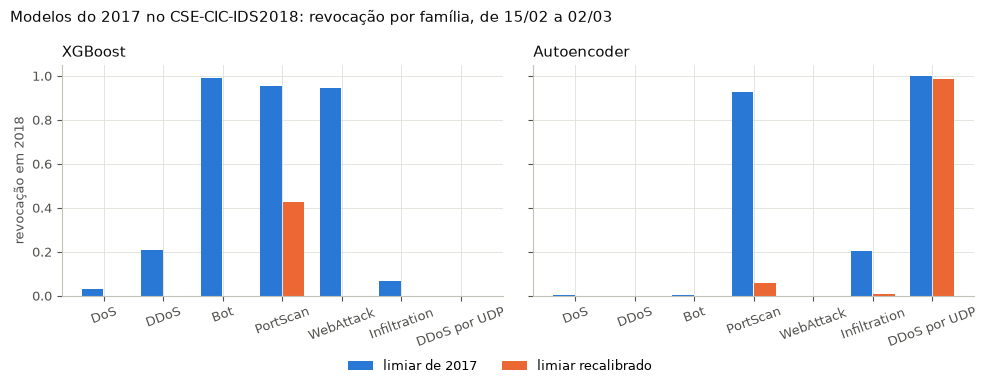

In [6]:
# A força bruta só existe no dia da calibração; o DDoS por UDP entra no lugar dela
groups = [f for f in FAMILIES if f != "BruteForce"] + ["DDoS por UDP"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
x = np.arange(len(groups))
for ax, name in zip(axes, ("xgb_temporal", "ae_unseen"), strict=True):
    for i, threshold in enumerate(COLORS):
        values = [recalibrated[(LABELS[name], threshold)][g] for g in groups]
        ax.bar(x + (i - 0.5) * 0.38, values, width=0.36, color=COLORS[threshold], label=threshold)
    ax.set_xticks(x, groups, rotation=20)
    ax.set_title(LABELS[name], loc="left", color=INK)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("revocação em 2018")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(
    "Modelos do 2017 no CSE-CIC-IDS2018: revocação por família, de 15/02 a 02/03",
    x=0.01,
    ha="left",
    color=INK,
)
fig.tight_layout()
fig.savefig(FIGURES / "outra_rede_revocacao.png", bbox_inches="tight")
plt.show()

**Leitura.** Recalibrar com um dia normal controla os falsos positivos, mas a detecção some:

- O XGBoost dá probabilidade de ataque praticamente igual a 1 a mais de 1 % dos fluxos normais de
  14/02, então o limiar recalibrado vai para perto de 1. A taxa de falsos positivos cai para 0,1 %,
  e ele só continua pegando 42 % do PortScan (1,1 % dos ataques).
- O autoencoder fica com 0,3 % de falsos positivos e pega 99 % do DDoS por UDP e 6 % do PortScan; o
  Isolation Forest para de alarmar.
- Juntos, XGBoost e autoencoder detectam 1,3 % dos ataques, com 0,4 % de falsos positivos.

Sem exemplos de ataque da rede nova, nenhum limiar salva modelos treinados em outra rede: eles não
separam o ataque do normal de 2018.

## 5. A ordem dos scores

O ROC-AUC por família mede se o modelo ainda põe os ataques acima dos fluxos normais, qualquer que
seja o limiar. Para caber na memória e no tempo, os normais são uma amostra aleatória de 2 milhões.

In [7]:
rng = np.random.default_rng(0)
sample = rng.choice(np.flatnonzero(benign), 2_000_000, replace=False)
auc = {}
for name in MODELS:
    s = scores[name].to_numpy()
    auc[LABELS[name]] = {
        f: roc_auc_score(
            np.r_[np.ones((family == f).sum()), np.zeros(len(sample))],
            np.r_[s[family == f], s[sample]],
        )
        for f in FAMILIES
    }
display(pd.DataFrame(auc).map(fmt))

,XGBoost,XGBoost sem TCP,Autoencoder,Isolation Forest
DoS,0.453,0.362,0.385,0.380
DDoS,0.291,0.761,0.591,0.674
Bot,0.936,0.989,0.607,0.779
BruteForce,0.893,0.938,0.536,0.606
PortScan,0.981,0.984,0.961,0.973
WebAttack,0.975,0.990,0.804,0.837
Infiltration,0.617,0.690,0.814,0.804


**Leitura.** A ordem dos scores confirma: os modelos de 2017 põem o DoS de 2018 abaixo dos fluxos
normais (ROC-AUC de 0,36 a 0,45, pior que o acaso) e, com os atributos de TCP, também o DDoS (0,29).
Sem esses atributos, o XGBoost ordena melhor em cinco das sete famílias: DDoS de 0,29 para 0,76,
Bot de 0,94 para 0,99, força bruta de 0,89 para 0,94, ataques web de 0,975 para 0,990 e
infiltração de 0,62 para 0,69. A suspeita da etapa 2 ganha apoio: a janela TCP ajuda a reconhecer
as máquinas de 2017 e atrapalha diante de máquinas novas. O PortScan é a família que todos os
modelos ordenam bem (0,96 a 0,98).

## 6. Conclusões

1. **Os modelos não transferem de uma rede de laboratório para outra.** Com o limiar de 2017, os
   falsos positivos vão de 3 % a 11 % dos fluxos normais (milhões de alarmes) e a revocação total
   fica em 18 % no melhor caso. DoS e DDoS, 91 % dos ataques, não são reconhecidos.
2. **Recalibrar só com tráfego normal não resolve:** os falsos positivos caem para menos de 0,5 %,
   mas a revocação vai junto (1,3 % na combinação). Um IDS treinado numa rede precisa de exemplos
   de ataque, ou de um novo treino, na rede onde vai rodar.
3. **O atalho do protocolo é real:** o classificador deixa passar o DDoS por UDP, e o autoencoder o
   pega inteiro, mesmo recalibrado. É o argumento mais claro para combinar os dois.
4. **A janela TCP atrapalha a transferência:** sem ela, o XGBoost ordena melhor em cinco das sete
   famílias.
5. **O que transfere:** a varredura de portas (todos os modelos) e, no XGBoost com o limiar de 2017,
   Bot, ataques web e força bruta SSH.

**Ressalvas.** Os dois conjuntos são de laboratório e do mesmo grupo; a rede de 2018 é maior e está
na AWS. Sem remoção de duplicatas no 2018, fluxos repetidos pesam mais. E metade do DDoS por UDP sai
na limpeza por ter o tamanho do cabeçalho estourado.